In [ ]:
import os
import re
import time
import base64
from io import BytesIO
from dataclasses import dataclass
from typing import Optional, List, Tuple, Dict

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from datasets import load_dataset
from openai import OpenAI
import warnings

warnings.filterwarnings("ignore")
os.environ["OPENAI_API_KEY"] = ""

VLM_MODEL = "gpt-5-mini"
client = OpenAI()

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)

print(f"Using device: {DEVICE}")

Device: mps   model: gpt-5-mini 


---
# 1) Thinking Mode: CoT Over Images

A VLM asked "what is the value of the largest bar?" can answer in one shot. 

Asked "how much did the top two categories change between 2014 and 2019?". It has to read four numbers off the axes
and do arithmetic — and a single forward pass through the answer tokens gives it nowhere to put
the intermediate work. 

**Thinking mode** buys that space: the model spends tokens reasoning
before it commits to an answer.

Two shapes in production, same idea:

| | Where the reasoning lives | How you control it |
|---|---|---|
| Open weights (Qwen3-VL-Thinking, GLM-4.1V-Thinking) | emitted in the output text between `<think>...</think>` | prompt, and where you cut generation |
| Hosted reasoning models (GPT-5, o-series) | server-side, never returned | a `reasoning.effort` knob, billed as reasoning tokens |

16 ChartQA samples


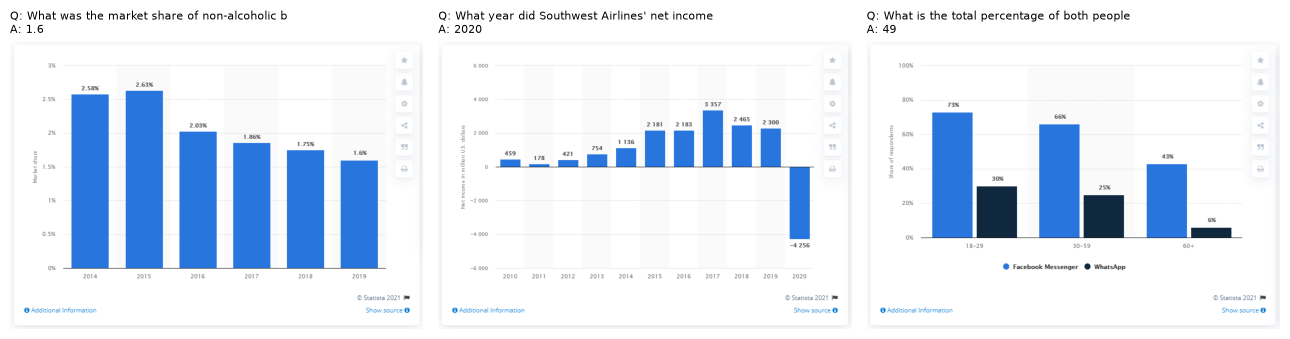

In [2]:
# ----- Common Utils ----------
def load_chartqa(split: str = "val", n: int = 16, seed: int = 0) -> list[dict]:
    """Real (chart, question, answer) triples — the same source used in notebook 03."""
    ds = (
        load_dataset("HuggingFaceM4/ChartQA", split=split)
        .shuffle(seed=seed)
        .select(range(n))
    )
    return [
        {
            "image": r["image"].convert("RGB"),
            "question": r["query"],
            "answer": r["label"][0],
        }
        for r in ds
    ]


def encode_image(image, max_side: int = 768) -> str:
    """PIL image → data URL. Downscaled first: the API bills image tokens by area."""
    img = image.copy()
    img.thumbnail((max_side, max_side))
    buf = BytesIO()
    img.save(buf, format="PNG")
    return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()


def normalize(s: str) -> str:
    return re.sub(r"[\s%$,]", "", s.strip().lower().rstrip(".").strip())


def relaxed_match(pred: str, gold: str, tol: float = 0.05) -> bool:
    """ChartQA relaxed accuracy: string match, or numeric match within 5%."""
    p, g = normalize(pred), normalize(gold)
    if p == g:
        return True
    try:
        pn = float(re.sub(r"[^0-9.\-]", "", p)) if re.search(r"\d", p) else None
        gn = float(re.sub(r"[^0-9.\-]", "", g)) if re.search(r"\d", g) else None
    except ValueError:
        return False
    return pn is not None and gn is not None and abs(pn - gn) <= tol * abs(gn)


SAMPLES = load_chartqa(n=16)
print(f"{len(SAMPLES)} ChartQA samples")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, s in zip(axes, SAMPLES[:3]):
    ax.imshow(s["image"])
    ax.axis("off")
    ax.set_title(f"Q: {s['question'][:44]}\nA: {s['answer']}", fontsize=8, loc="left")
plt.tight_layout()
plt.show()

Two details that decide whether this works at all:

1. **`max_output_tokens` covers reasoning too.** Reasoning tokens are billed and counted against
that limit before a single visible character is produced. Set it to 32 "because the answer is
one word" and a high-effort call returns an *empty string* — the budget was consumed thinking.
This is the most common way a reasoning-model integration fails silently.

2. **Image detail costs tokens.** The chart is downscaled to 768px before encoding; a full
resolution scan would cost several times the input tokens for a chart whose labels are already
legible.

In [3]:
ANSWER_HINT = "Answer the question using a single word or phrase."


def ask(sample: dict, effort: str = "low", max_output_tokens: int = 2048) -> dict:
    """One image+question call. Returns the answer plus what the reasoning cost."""
    t0 = time.time()
    resp = client.responses.create(
        model=VLM_MODEL,
        reasoning={"effort": effort},
        max_output_tokens=max_output_tokens,
        input=[
            {
                "role": "user",
                "content": [
                    {
                        "type": "input_text",
                        "text": f"{sample['question']}\n{ANSWER_HINT}",
                    },
                    {
                        "type": "input_image",
                        "image_url": encode_image(sample["image"]),
                        "detail": "auto",
                    },
                ],
            }
        ],
    )
    return {
        "answer": resp.output_text.strip(),
        "reasoning_tokens": resp.usage.output_tokens_details.reasoning_tokens,
        "output_tokens": resp.usage.output_tokens,
        "input_tokens": resp.usage.input_tokens,
        "seconds": time.time() - t0,
    }


demo = SAMPLES[0]
print(f"Q: {demo['question']}\nGold: {demo['answer']}\n")

for effort in ("minimal", "high"):
    r = ask(demo, effort=effort)
    print(
        f"  effort={effort:<8} answer={r['answer'][:30]!r:5s} "
        f"reasoning={r['reasoning_tokens']:>5} tok   "
        f"visible={r['output_tokens'] - r['reasoning_tokens']:>3} tok   "
        f"{r['s' \
        'econds']:.1f}s"
    )

Q: What was the market share of non-alcoholic beer in Italy in 2019?
Gold: 1.6

  effort=minimal  answer='1.6%' reasoning=    0 tok   visible= 22 tok   2.9s
  effort=high     answer='1.6%' reasoning=  128 tok   visible= 36 tok   3.8s


### Which questions actually need to think?

- A router should spend reasoning tokens only where they buy accuracy.
- Keywords in the question cannot decide that — difficulty lives in the *image*. "How many
  people are here?" is trivial for a portrait, hard for a crowd.
- So measure it: run the same samples at both ends of the effort range, and see per question
  whether more thinking flipped it wrong → right, and what it cost.
- The questions that flip are the routing signal. Distil that label into a cheap classifier, or
  route on the model's own one-token judgement — either way the threshold comes from this
  measurement, not a word list.

effort=minimal  relaxed  62.5%        0 reasoning tok/q     1.5s/q
effort=low      relaxed  62.5%       44 reasoning tok/q     2.0s/q
effort=high     relaxed  68.8%      392 reasoning tok/q     4.7s/q

rescued by thinking (2):
   How much was eBay's net revenue in the most recent fiscal year?
   What is the difference between Carex and Palmolive?
regressed (1): ['The bar chart covers how many years?']


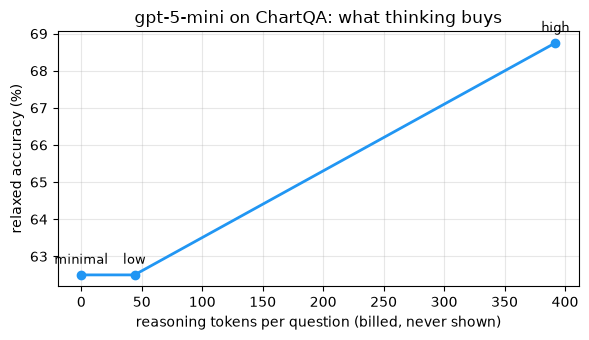

In [ ]:
EFFORTS = ["minimal", "low", "high"]

results = {}
for effort in EFFORTS:
    runs = [ask(s, effort=effort) for s in SAMPLES]
    correct = [relaxed_match(r["answer"], s["answer"]) for r, s in zip(runs, SAMPLES)]
    results[effort] = {
        "accuracy": sum(correct) / len(correct),
        "reasoning": np.mean([r["reasoning_tokens"] for r in runs]),
        "seconds": np.mean([r["seconds"] for r in runs]),
        "correct": correct,
    }
    print(
        f"effort={effort:<8} relaxed {results[effort]['accuracy']:6.1%}   "
        f"{results[effort]['reasoning']:6.0f} reasoning tok/q   "
        f"{results[effort]['seconds']:5.1f}s/q"
    )

# Which questions did the extra thinking actually rescue?
lo, hi = results[EFFORTS[0]]["correct"], results[EFFORTS[-1]]["correct"]
flipped = [i for i, (a, b) in enumerate(zip(lo, hi)) if b and not a]
broke = [i for i, (a, b) in enumerate(zip(lo, hi)) if a and not b]
print(f"\nrescued by thinking ({len(flipped)}):")
for i in flipped:
    print(f"   {SAMPLES[i]['question'][:70]}")
print(f"regressed ({len(broke)}): {[SAMPLES[i]['question'][:50] for i in broke]}")

fig, ax = plt.subplots(figsize=(6, 3.5))
x = [results[e]["reasoning"] for e in EFFORTS]
y = [results[e]["accuracy"] * 100 for e in EFFORTS]
ax.plot(x, y, "o-", color="#2196F3", linewidth=2)
for e, xi, yi in zip(EFFORTS, x, y):
    ax.annotate(
        e, (xi, yi), textcoords="offset points", xytext=(0, 8), fontsize=9, ha="center"
    )
ax.set_xlabel("reasoning tokens per question")
ax.set_ylabel(" Accuracy (%)")
ax.set_title(f"What thinking buys")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
# 2) Thinking Block

In [ ]:
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration

THINK_MODEL = "Qwen/Qwen3-VL-2B-Thinking"
DTYPE = (
    torch.bfloat16
    if DEVICE.type == "mps"
    or (DEVICE.type == "cuda" and torch.cuda.is_bf16_supported())
    else torch.float16 if DEVICE.type == "cuda" else torch.float32
)

# max_pixels caps the visual token budget: after the 2x2 spatial merge one token covers 32x32 px
processor = AutoProcessor.from_pretrained(THINK_MODEL, max_pixels=384 * 32 * 32)
qwen = (
    Qwen3VLForConditionalGeneration.from_pretrained(THINK_MODEL, dtype=DTYPE)
    .to(DEVICE)
    .eval()
)
tk = processor.tokenizer

OPEN_THINK = tk.convert_tokens_to_ids("<think>")
END_THINK = tk.convert_tokens_to_ids("</think>")
IM_END = tk.convert_tokens_to_ids("<|im_end|>")
IMAGE_TOKEN = qwen.config.image_token_id
CLOSE_IDS = tk(
    "\n</think>\n\n", add_special_tokens=False, return_tensors="pt"
).input_ids.to(DEVICE)
WAIT_IDS = tk("\nWait,", add_special_tokens=False, return_tensors="pt").input_ids.to(
    DEVICE
)

print(
    f"{THINK_MODEL}   {sum(p.numel() for p in qwen.parameters()) / 1e9:.2f}B params   {DTYPE}"
)
print(
    f"<think>={OPEN_THINK}   </think>={END_THINK}   "
    f"special={tk.added_tokens_decoder[END_THINK].special}   vocab={qwen.config.text_config.vocab_size}"
)

Qwen/Qwen3-VL-2B-Thinking   2.13B params   torch.bfloat16
<think>=151667   </think>=151668   special=False   vocab=151936


## 2.1 Special Think Token

`</think>` is id **151668**, and `special=False`

A Thinking checkpoint's chat template ends the prompt with `<|im_start|>assistant\n<think>\n` — the *opening* tag is written by the template, before the model runs. 
The model never decides to start reasoning; it is started for it. Emitting `</think>` is the
only decision it makes about its own budget, and that single token is the whole control surface

In [12]:
def chat_messages(sample: dict) -> list[dict]:
    return [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": sample["image"]},
                {"type": "text", "text": f"{sample['question']}\n{ANSWER_HINT}"},
            ],
        }
    ]


def build_inputs(sample: dict) -> dict:
    return processor.apply_chat_template(
        chat_messages(sample),
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    ).to(DEVICE)


def generate(inputs: dict, max_new_tokens: int = 512, seed: int = 0) -> dict:
    """One sampled generation, keeping the raw per-step logits for the analysis below."""
    torch.manual_seed(seed)
    out = qwen.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=True,
        temperature=1.0,
        top_p=0.95,
        top_k=20,
        return_dict_in_generate=True,
        output_logits=True,
    )

    new = out.sequences[0, inputs["input_ids"].shape[1] :]
    hit = (new == END_THINK).nonzero()

    # boundary by token id, never by string search
    cut = int(hit[0]) if len(hit) else len(new)

    return {
        "sequences": out.sequences,
        "new": new,
        "cut": cut,
        "logits": torch.stack(out.logits, 0).float().squeeze(1),  # [steps, vocab]
        "reasoning": tk.decode(new[:cut]).strip(),
        "answer": tk.decode(new[cut + 1 :], skip_special_tokens=True).strip(),
    }


demo = SAMPLES[2]
inputs = build_inputs(demo)
prompt_text = processor.apply_chat_template(
    chat_messages(demo), add_generation_prompt=True, tokenize=False
)

print(f"prompt ends with: {prompt_text[-42:]!r}\n")
r = generate(inputs)
print(f"Q: {demo['question']}\nGold: {demo['answer']}")
print(f"[reasoning] {r['reasoning']}\n\n[answer]    {r['answer']}")

prompt ends with: '.<|im_end|>\n<|im_start|>assistant\n<think>\n'

Q: What is the total percentage of both people using Facebook and WhatsApp at 60+
Gold: 49
[reasoning] Got it, let's look at the bar chart. For the 60+ age group, Facebook Messenger is 43% and WhatsApp is 6%. We need to add those two percentages together. 43 + 6 = referencing the numbers in the chart. So the total is 49.

[answer]    49


## 2.2 Reasoning Effort

- **Ceiling.** Budget exhausted and the model has not stopped? Write `</think>` into the stream
  yourself. Whatever it had at that moment is what it has to answer with.
- **Floor.** Model emitted `</think>` too early? Delete it and append `"Wait,"`. This is *budget
  forcing* (Muennighoff et al., 2025), and the continuation is not padding — the model
  re-derives, and frequently double-checks its own arithmetic against the chart.

That is the entire mechanism. A serving stack does the same thing more cheaply — the ceiling as a
`-inf` mask on every logit except `</think>`, the floor as a `-inf` mask on `</think>` alone — so it
never has to restart generation. The loop below is written the explicit way because the point is to
watch it happen.

In [14]:
def think_with_budget(
    sample: dict,
    min_think: int = 0,
    max_think: int = 512,
    max_waits: int = 4,
    answer_tokens: int = 48,
) -> dict:
    """s1-style budget forcing: extend the block with 'Wait,', or cut it by writing </think>."""

    inputs = build_inputs(sample)
    prompt_len = inputs["input_ids"].shape[1]
    vision = {k: inputs[k] for k in ("pixel_values", "image_grid_thw")}
    ids, waits = inputs["input_ids"], 0

    def mm_ids(n: int) -> torch.Tensor:
        """Image positions are fixed by the prompt; everything generated afterwards is text."""
        m = torch.zeros((1, n), dtype=inputs["mm_token_type_ids"].dtype, device=DEVICE)
        m[:, :prompt_len] = inputs["mm_token_type_ids"]
        return m

    while True:
        room = max(1, max_think - (ids.shape[1] - prompt_len))

        # stop the moment it wants out
        ids = qwen.generate(
            input_ids=ids,
            attention_mask=torch.ones_like(ids),
            mm_token_type_ids=mm_ids(ids.shape[1]),
            **vision,
            max_new_tokens=room,
            do_sample=True,
            temperature=1.0,
            top_p=0.95,
            top_k=20,
            eos_token_id=[END_THINK, IM_END],
        )

        stopped_early = (
            ids[0, -1] == END_THINK and (ids.shape[1] - prompt_len) < min_think
        )
        if not (stopped_early and waits < max_waits):
            break
        # floor: drop </think>, say "Wait,"
        ids = torch.cat([ids[:, :-1], WAIT_IDS], 1)
        waits += 1

    # ceiling: close the block ourselves
    if ids[0, -1] != END_THINK:
        ids = torch.cat([ids, CLOSE_IDS], 1)
    think_tokens = ids.shape[1] - prompt_len

    out = qwen.generate(
        input_ids=ids,
        attention_mask=torch.ones_like(ids),
        mm_token_type_ids=mm_ids(ids.shape[1]),
        **vision,
        max_new_tokens=answer_tokens,
        do_sample=True,
        temperature=1.0,
        top_p=0.95,
        top_k=20,
        return_dict_in_generate=True,
        output_logits=True,
    )

    p0 = out.logits[0].float().softmax(-1)
    return {
        "think_tokens": think_tokens,
        "waits": waits,
        "answer": tk.decode(
            out.sequences[0, ids.shape[1] :], skip_special_tokens=True
        ).strip(),
        "first_token_entropy": float(-(p0 * p0.clamp_min(1e-9).log()).sum()),
        "trace": tk.decode(ids[0, prompt_len:]),
    }


BUDGETS = {
    "starved (max 16)": dict(max_think=16),
    "clipped (max 64)": dict(max_think=64),
    "natural": dict(),
    "extended (min 256)": dict(min_think=256),
}

for name, kwargs in BUDGETS.items():
    b = think_with_budget(demo, **kwargs)
    print(
        f"{name:<20} {b['think_tokens']:>4} think tok   {b['waits']} waits   "
        f"H(first answer token)={b['first_token_entropy']:.2f}   answer={b['answer'][:44]!r}"
    )

print(f"\nGold: {demo['answer']}")

starved (max 16)       19 think tok   0 waits   H(first answer token)=0.98   answer='6% + 43% = 49%'
clipped (max 64)       59 think tok   0 waits   H(first answer token)=0.00   answer='49'
natural                86 think tok   0 waits   H(first answer token)=0.00   answer='49'
extended (min 256)    180 think tok   4 waits   H(first answer token)=0.00   answer='49'

gold: 49


starved (max 16)         19 think tok/q   relaxed  50.0%   H(first answer token) 0.19   25s
clipped (max 64)         65 think tok/q   relaxed  62.5%   H(first answer token) 0.01   45s
natural                  98 think tok/q   relaxed  62.5%   H(first answer token) 0.00   71s
extended (min 256)      270 think tok/q   relaxed  62.5%   H(first answer token) 0.00   235s


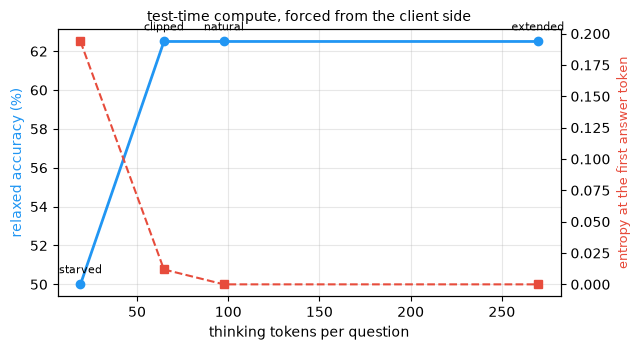

In [15]:
EVAL = SAMPLES[:8]

curve = {}
for name, kwargs in BUDGETS.items():
    t0 = time.time()
    runs = [think_with_budget(s, **kwargs) for s in EVAL]
    curve[name] = {
        "accuracy": np.mean(
            [relaxed_match(b["answer"], s["answer"]) for b, s in zip(runs, EVAL)]
        ),
        "think": np.mean([b["think_tokens"] for b in runs]),
        "entropy": np.mean([b["first_token_entropy"] for b in runs]),
    }
    print(
        f"{name:<20} {curve[name]['think']:6.0f} think tok/q   "
        f"relaxed {curve[name]['accuracy']:6.1%}   "
        f"H(first answer token) {curve[name]['entropy']:.2f}   {time.time() - t0:.0f}s"
    )

fig, ax = plt.subplots(figsize=(6.5, 3.6))
x = [curve[n]["think"] for n in BUDGETS]
ax.plot(
    x, [curve[n]["accuracy"] * 100 for n in BUDGETS], "o-", color="#2196F3", linewidth=2
)
for n, xi in zip(BUDGETS, x):
    ax.annotate(
        n.split(" ")[0],
        (xi, curve[n]["accuracy"] * 100),
        textcoords="offset points",
        xytext=(0, 8),
        fontsize=8,
        ha="center",
    )
ax.set_xlabel("thinking tokens per question")
ax.set_ylabel("relaxed accuracy (%)", color="#2196F3")

ax2 = ax.twinx()
ax2.plot(
    x, [curve[n]["entropy"] for n in BUDGETS], "s--", color="#E74C3C", linewidth=1.5
)
ax2.set_ylabel("entropy at the first answer token", color="#E74C3C", fontsize=9)

ax.set_title("test-time compute, forced from the client side", fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
# 3) Visual Grounding: Boxes as Output

The one capability with no text-only analogue: the model does not just say what it sees, it
says *where*.

- No separate box head. Qwen2-VL, Qwen2.5-VL and Kosmos-2 all emit coordinates through the
  ordinary LM head — grounding is a *formatting* skill learned in post-training, not an
  architectural addition.
- Two encodings in the wild: coordinates as plain text (Qwen-VL, on a 0–1000 normalised grid),
  or as dedicated `<loc_0>…<loc_1023>` vocabulary tokens (Kosmos-2). Both decode like any
  other token.
- Which means the client-side work is parsing, validating and scoring — not modelling.
- **RefCOCO** is the benchmark: a referring expression ("bowl of carrots", "little girl") plus
  one gold box. Scored by IoU, with IoU ≥ 0.5 counted as a hit.

`gpt-5-mini` is a general-purpose model, not a grounding-tuned one, so treat the numbers below
as a floor — the point is that the whole loop is real and measurable.

In [17]:
from itertools import islice

# Qwen-VL's convention: coordinates on a 0-1000 grid, resolution independent
GRID = 1000
LOCATE_PROMPT = (
    "Give the bounding box of: {expr}\n"
    "Reply with only four integers on a 0-{grid} grid: x_min, y_min, x_max, y_max, "
    "comma separated, where 0 is the left/top edge and {grid} the right/bottom edge. "
    "No other text."
)


def load_refcoco(n: int = 6, split: str = "val") -> list[dict]:
    """Referring expression + gold box. RefCOCO stores COCO-style [x, y, w, h] pixels."""
    ds = load_dataset("lmms-lab/RefCOCO", split=split, streaming=True)
    out = []
    for r in islice(ds, n):
        w, h = r["image"].size
        x, y, bw, bh = r["bbox"]
        out.append(
            {
                "image": r["image"].convert("RGB"),
                "expression": r["answer"][0],
                # normalise to [0, 1] so every box in this section shares one convention
                "gold": [x / w, y / h, (x + bw) / w, (y + bh) / h],
            }
        )
    return out


class GroundingOutputParser:
    """Parse and validate bounding boxes that arrive as generated text."""

    @staticmethod
    def parse_text_bbox(text: str) -> Optional[Dict]:
        """Accept '<box>(a, b, c, d)</box>' or a bare 'a, b, c, d'. Returns [0,1] coords."""
        m = re.search(r"<box>\s*\(([^)]+)\)\s*</box>", text) or re.search(
            r"(-?[\d.]+(?:\s*,\s*-?[\d.]+){3})", text
        )
        if not m:
            return None
        coords = [float(c) for c in re.split(r"\s*,\s*", m.group(1).strip())]
        # A model told to use the 0-1000 grid returns integers; rescale to [0, 1].
        if max(coords) > 1.0:
            coords = [c / GRID for c in coords]
        return {"bbox": coords, "valid": GroundingOutputParser.validate_bbox(coords)}

    @staticmethod
    def validate_bbox(bbox: List[float]) -> bool:
        """Check that coordinates are well-formed."""
        x_min, y_min, x_max, y_max = bbox
        in_range = all(0.0 <= c <= 1.0 for c in bbox)
        valid_order = x_min < x_max and y_min < y_max
        min_area = (x_max - x_min) * (y_max - y_min) > 0.001
        return in_range and valid_order and min_area

    @staticmethod
    def compute_iou(bbox_a: List[float], bbox_b: List[float]) -> float:
        """Intersection over Union between two bounding boxes."""
        x1 = max(bbox_a[0], bbox_b[0])
        y1 = max(bbox_a[1], bbox_b[1])
        x2 = min(bbox_a[2], bbox_b[2])
        y2 = min(bbox_a[3], bbox_b[3])

        intersection = max(0, x2 - x1) * max(0, y2 - y1)
        area_a = (bbox_a[2] - bbox_a[0]) * (bbox_a[3] - bbox_a[1])
        area_b = (bbox_b[2] - bbox_b[0]) * (bbox_b[3] - bbox_b[1])
        union = area_a + area_b - intersection

        return intersection / union if union > 0 else 0.0


def locate(sample: dict, effort: str = "low") -> Optional[Dict]:
    """Ask the model where something is, and parse the box out of its text."""
    resp = client.responses.create(
        model=VLM_MODEL,
        reasoning={"effort": effort},
        max_output_tokens=2048,
        input=[
            {
                "role": "user",
                "content": [
                    {
                        "type": "input_text",
                        "text": LOCATE_PROMPT.format(
                            expr=sample["expression"], grid=GRID
                        ),
                    },
                    {
                        "type": "input_image",
                        "image_url": encode_image(sample["image"], max_side=1024),
                        "detail": "high",
                    },
                ],
            }
        ],
    )
    return GroundingOutputParser.parse_text_bbox(resp.output_text)


REF_SAMPLES = load_refcoco(n=6)
parser = GroundingOutputParser()

for s in REF_SAMPLES:
    pred = locate(s)
    s["pred"] = pred["bbox"] if pred and pred["valid"] else None
    s["iou"] = parser.compute_iou(s["pred"], s["gold"]) if s["pred"] else 0.0
    print(
        f"{s['expression'][:44]:<46} IoU {s['iou']:.3f}"
        f"{'' if s['pred'] else '   (unparseable or invalid box)'}"
    )

ious = [s["iou"] for s in REF_SAMPLES]
print(
    f"\nmean IoU {np.mean(ious):.3f}   acc@0.5 {np.mean([i >= 0.5 for i in ious]):.1%}"
)

bowl behind the others can only see part       IoU 0.000
front bowl w/carrots in it                     IoU 0.476
little girl                                    IoU 0.264
green woman                                    IoU 0.504
mom                                            IoU 0.492
child sitting on womans lap                    IoU 0.193

mean IoU 0.321   acc@0.5 16.7%


Gold box in green, model prediction in red. IoU is the overlap fraction — the gap between the
two rectangles is what the metric is actually counting.

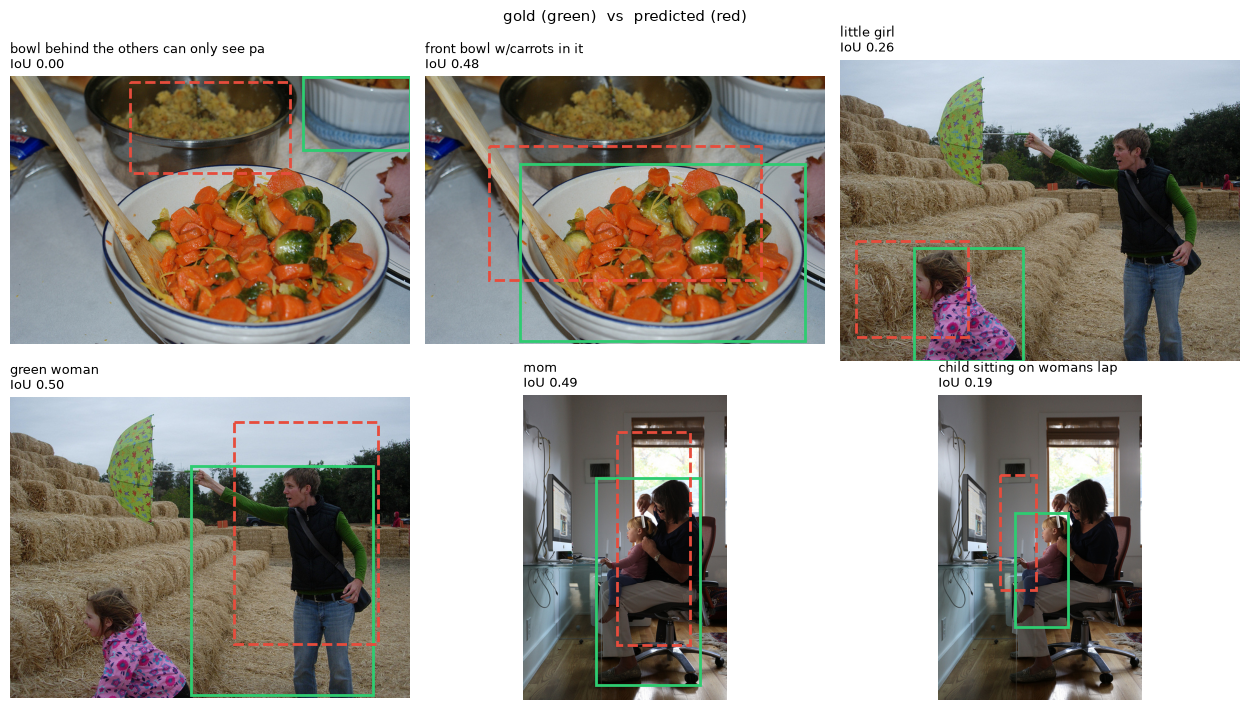

In [18]:
def visualize_grounding(samples: List[Dict], cols: int = 3):
    """Draw gold vs predicted boxes on the real images."""
    rows = (len(samples) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 3.6 * rows))

    for ax, s in zip(np.ravel(axes), samples):
        w, h = s["image"].size
        ax.imshow(s["image"])

        for bbox, color, style in [
            (s["gold"], "#2ECC71", "-"),
            (s["pred"], "#E74C3C", "--"),
        ]:
            if bbox is None:
                continue
            ax.add_patch(
                patches.Rectangle(
                    (bbox[0] * w, bbox[1] * h),
                    (bbox[2] - bbox[0]) * w,
                    (bbox[3] - bbox[1]) * h,
                    linewidth=2,
                    edgecolor=color,
                    linestyle=style,
                    facecolor="none",
                )
            )

        ax.set_title(
            f"{s['expression'][:38]}\nIoU {s['iou']:.2f}", fontsize=9, loc="left"
        )
        ax.axis("off")

    for ax in np.ravel(axes)[len(samples) :]:
        ax.axis("off")

    plt.suptitle("gold (green)  vs  predicted (red)", fontsize=11)
    plt.tight_layout()
    plt.show()


visualize_grounding(REF_SAMPLES)